# `nn_l1_sbi` — reproduce the paper

*Tomographic weak-lensing SBI with starlet $\ell_1$-norm summaries vs a CNN.*

This notebook has three sections, in increasing order of cost. **Run-all is safe on a
laptop**: sections B and C do nothing but print a status report unless their inputs /
opt-in flag are present.

| section | what it produces | hardware | wall time | needs |
|---|---|---|---|---|
| **A — Table 1** | the 12-row Table 1 (FoM$_3\pm$, $\sigma(\Omega_{\rm m})$, $\sigma(\sigma_8)$, $\sigma(w_0)$, bias) + assertions | CPU, 1 core | **< 1 s** | nothing but this repo (`data/table1/`, 60 JSON files / 43 kB, committed) |
| **B — Figures** | the paper figures whose inputs survive | CPU | seconds to ~10 min per figure | the Zenodo data bundle (`$NN_L1_SBI_DATA`) for most |
| **C — End-to-end** | one VMIM compressor retrained from scratch + its population sweep | **1 GPU** | **~1 h** | `NN_L1_SBI_GPU=1` + the raw $\ell_1$ caches |

Dependencies: section A needs only `numpy` (plus the standard library). Section B needs
`matplotlib` and, per figure, `getdist` / `healpy` / `tarp` / `scikit-learn`. Section C
needs the full pinned GPU environment (`environment.yml` + `constraints.txt`).

Nothing in this notebook downloads anything.

---

# Section A — Table 1

**CPU · no network · well under a second.**

Everything here is read from `data/table1/`, which is committed to this repository
(60 JSON files totalling 43 kB, plus a `README.md`). No download, no GPU, no Zenodo access. The per-observation products
(`per_patch_metrics.npz`, 153 MB; `per_obs_samples.npy`, 216 MB) are *not* needed: each
`median_summary.json` is a verified digest of them (`fom3` equals
`np.median(per_patch_metrics['fom3'])` to full float precision).

### A.1 — Locate the committed Table-1 bundle *(instant)*

Finds the repository that holds `data/table1/`, then loads `arms.json` and the four
precomputed cross-check JSONs. Three sources are tried, in order:

1. `$NN_L1_SBI_REPO`, if set — explicit, wins, and is validated;
2. `nn_l1_sbi.paths.table1_dir()`, if the package is importable (`pip install -e .`, or
   `src/` already on `PYTHONPATH`). It resolves from the package's own `__file__`, so it
   works **from any working directory**;
3. a walk up from the current directory — the bare-clone fallback, and the only one of the
   three that depends on where you launched Jupyter from.

> **The one trap in this section.** An arm label is *never* a directory name.
> `l1 +conv+product` maps to sweep dirs called `joint_l1_*` / `joint_bnt_*` (underscore),
> while the separate `joint l1` arm maps to `jointl1_*` (no underscore) — two different
> runs with different numbers. Directories are resolved **only** through `arms.json`.

In [1]:
import json
import os
from pathlib import Path

import numpy as np


def _is_clone(p):
    # A source clone, not an unpacked data bundle: it carries BOTH the committed Table-1
    # bundle and the packaging metadata. (Section B additionally needs the clone's src/.)
    return (p / "data" / "table1" / "arms.json").is_file() and (p / "pyproject.toml").is_file()


def find_repo_root(start=None):
    # 1. $NN_L1_SBI_REPO wins, and is validated.
    env = os.environ.get("NN_L1_SBI_REPO")
    if env:
        p = Path(env).expanduser().resolve()
        if (p / "data" / "table1" / "arms.json").is_file():
            return p
        raise FileNotFoundError(f"NN_L1_SBI_REPO={p} has no data/table1/arms.json")

    # 2. The package, if it is importable: nn_l1_sbi.paths resolves the bundle from its own
    #    __file__, so this branch does not care what the working directory is.
    try:
        from nn_l1_sbi.paths import table1_dir
    except ImportError:                 # bare clone, package not installed -- fall through
        pass
    else:
        # table1_dir() is <clone>/data/table1 for a source clone, but $NN_L1_SBI_DATA/table1
        # for an installed package pointed at the Zenodo bundle. Accept only the clone.
        cand = table1_dir().expanduser().resolve().parent.parent
        if _is_clone(cand):
            return cand

    # 3. Bare clone with the package not installed: walk up from `start` (default: the cwd).
    here = Path(start or os.getcwd()).resolve()
    for p in (here, *here.parents):
        if (p / "data" / "table1" / "arms.json").is_file():
            return p
    raise FileNotFoundError(
        "cannot find the repository root: nn_l1_sbi.paths is not importable and there is no "
        f"data/table1/arms.json at or above {here}. Set NN_L1_SBI_REPO=<path to the "
        "nn_l1_sbi checkout>, or install the package (pip install -e .).")


REPO = find_repo_root()
T1 = REPO / "data" / "table1"


def load(rel):
    with open(T1 / rel) as fh:
        return json.load(fh)


ARMS = load("arms.json")                      # arm label -> {singles, ensemble, published, quoted}
EV2 = load("TABLE1_ERRORBARS_V2.json")        # cross-check: all 12 arms, FoM3
CONV = load("TABLE1_CONV_ARMS.json")          # cross-check: 4 conv arms, incl. the sigma triplets
PAPER = load("TABLE1_PAPER.json")             # cross-check: 8 main rows, paper-facing digest
MARG = load("TABLE1_MARGINALS_NEW.json")      # cross-check: 2 new no-BNT conv rows, sigmas

n_files = sum(1 for _ in (T1 / "sweeps").rglob("median_summary.json"))
print(f"cwd           : {Path.cwd()}")
print(f"repo          : {REPO}")
print(f"table-1 bundle: {T1}")
print(f"arms          : {len(ARMS)}   sweep summaries on disk: {n_files}")
print(f"cross-checks  : TABLE1_ERRORBARS_V2 ({len(EV2)} arms), TABLE1_CONV_ARMS ({len(CONV)}), "
      f"TABLE1_PAPER ({len(PAPER)}), TABLE1_MARGINALS_NEW ({len(MARG)})")

cwd           : /path/to/workdir
repo          : /path/to/nn_l1_sbi
table-1 bundle: /path/to/nn_l1_sbi/data/table1
arms          : 12   sweep summaries on disk: 54
cross-checks  : TABLE1_ERRORBARS_V2 (12 arms), TABLE1_CONV_ARMS (4), TABLE1_PAPER (8), TABLE1_MARGINALS_NEW (2)


### A.2 — The recipe *(instant)*

Verbatim from `data/table1/README.md` §6 (= `docs/NOTE_FOM_ERROR_BARS.md` §5–6). Five rules,
all load-bearing:

1. **The `±` is always the standard deviation (`ddof=1`) over the three *pre-ensemble
   compressor* singles** `s41, s42, s43` — for *every* row, including the rows whose central
   value is an ensemble. It is carried as a **relative** quantity `std/mean` and multiplied by
   whichever central the row quotes, so the bar rescales correctly onto the published central.
2. **central** = the published value when there is one, otherwise the retrained value.
   Two rows (`l1 +conv, BNT`, `l1 +conv+product, BNT`) are new results with
   `published == null` and quote their retrained central.
3. **The single → ensemble shift is a *bias*.** It gets its own column and is **never**
   summed into the `±`.
4. The **σ centrals track the row's `quoted` estimator** (`s41` when `quoted == "single"`,
   the pooled ensemble otherwise). There are no published σ triplets to defer to.
5. Two quantities that are *not* the bar: `median_se` (block bootstrap over the 180 patches —
   a caption-only subdominant term, 0.16–0.31 %) and the leave-one-out jackknife in
   `final_bars_all_v2.json` (a diagnostic, never quotable).

Note the two independent meanings of "seed": `nde_seeds = [41, 42, 43]` are the three RealNVP
seeds *pooled inside every run* (identical for all 54 dirs), whereas the `s41/s42/s43` in the
*directory* name are the three independently trained **compressors** — those are what the error
bar is taken over.

In [2]:
PARAMS = ("sigma_Om", "sigma_s8", "sigma_w0")


def rel_spread(values):
    # THE error bar, as a relative quantity: std(ddof=1) / mean over the three singles.
    v = np.asarray(values, dtype=float)
    return float(np.std(v, ddof=1) / np.mean(v))


rows = []
for label, a in ARMS.items():
    # arm -> directory ONLY through arms.json; never string-munge the label.
    singles = [load(p) for p in a["singles"].values()]        # order: s41, s42, s43
    ens = load(a["ensemble"])
    src = singles[0] if a["quoted"] == "single" else ens      # s41 is index 0

    per_seed = [s["fom3"] for s in singles]
    rel = rel_spread(per_seed)                                # rule 1
    retrained = src["fom3"]
    central = a["published"] if a["published"] is not None else retrained   # rule 2
    pm = central * rel

    sig = [src[k] for k in PARAMS]                            # rule 4
    sig_rel = [rel_spread([s[k] for s in singles]) for k in PARAMS]
    sig_pm = [v * r for v, r in zip(sig, sig_rel)]

    mean_ps = float(np.mean(per_seed))
    bias_mean = 100.0 * (ens["fom3"] - mean_ps) / mean_ps     # rule 3, mean-relative
    bias_s41 = 100.0 * (ens["fom3"] - per_seed[0]) / per_seed[0]   # the stored convention

    summary, frame = (t.strip() for t in label.split(","))
    rows.append(dict(label=label, summary=summary, frame=frame, quoted=a["quoted"],
                     published=a["published"], retrained=retrained,
                     central=central, pm=pm, rel=rel,
                     per_seed=per_seed, mean=mean_ps,
                     std=float(np.std(per_seed, ddof=1)),
                     lo=float(min(per_seed)), hi=float(max(per_seed)),
                     ensemble=ens["fom3"], bias_mean=bias_mean, bias_s41=bias_s41,
                     sigma=sig, sigma_pm=sig_pm, sigma_rel=sig_rel,
                     sigma_ens=[ens[k] for k in PARAMS],
                     sigma_per_seed=[[s[k] for s in singles] for k in PARAMS]))

BY_LABEL = {r["label"]: r for r in rows}
print(f"built {len(rows)} rows from {3 * len(rows)} singles + {len(rows)} ensembles "
      f"= {4 * len(rows)} median_summary.json files")

built 12 rows from 36 singles + 12 ensembles = 48 median_summary.json files


### A.3 — Print Table 1 *(instant)*

12 rows = 6 summaries × 2 frames. `bias%` is the single → ensemble shift relative to the mean of
the three singles; it is **not** an error bar and is never folded into the `±`.

In [3]:
SEP = "-" * 116


def fmt_table(rows):
    out = [SEP,
           f"{'arm':<20}{'frame':<8}{'quoted':<10}{'FoM3 +-':>15}"
           f"{'sigma(Om)':>18}{'sigma(s8)':>18}{'sigma(w0)':>18}{'bias%':>9}",
           SEP]
    for r in rows:
        star = " " if r["published"] is not None else "*"
        fom = f"{r['central']:.0f} +- {r['pm']:.0f}{star}"
        sig = "".join(f"{v:.4f} +- {p:.4f}".rjust(18)
                      for v, p in zip(r["sigma"], r["sigma_pm"]))
        out.append(f"{r['summary']:<20}{r['frame']:<8}{r['quoted']:<10}{fom:>15}"
                   f"{sig}{r['bias_mean']:>+9.1f}")
    out.append(SEP)
    return "\n".join(out)


print("TABLE 1 -- FoM3 and marginal 1-sigma widths, 9000 mock observations per arm")
print(fmt_table(rows))
print("+- : std (ddof=1) over the three pre-ensemble compressor singles s41/s42/s43,")
print("     carried as std/mean and rescaled onto the quoted central. Same rule for the sigmas.")
print("*  : published == null (new result); the central is the retrained value.")
print("bias%: 100*(ensemble - mean(singles))/mean(singles). A bias, reported separately.")
print("     (TABLE1_ERRORBARS_V2.json stores the SAME shift with s41 as the baseline instead,")
print("      which for 'l1 auto, BNT' even flips the sign: +0.44 % vs -12.25 %. A.4 asserts")
print("      BOTH conventions. Either way it is never summed into the +-.)")

TABLE 1 -- FoM3 and marginal 1-sigma widths, 9000 mock observations per arm
--------------------------------------------------------------------------------------------------------------------
arm                 frame   quoted            FoM3 +-         sigma(Om)         sigma(s8)         sigma(w0)    bias%
--------------------------------------------------------------------------------------------------------------------
l1 auto             no-BNT  single        2448 +- 27   0.0503 +- 0.0001  0.0799 +- 0.0007  0.2340 +- 0.0022     -9.4
l1 auto             BNT     ensemble       388 +- 43   0.0861 +- 0.0035  0.1725 +- 0.0082  0.3191 +- 0.0057    -12.2
l1 +conv            no-BNT  single       2671 +- 133   0.0518 +- 0.0011  0.0814 +- 0.0021  0.2366 +- 0.0030     -5.4
l1 +conv            BNT     ensemble       458 +- 15*  0.0836 +- 0.0010  0.1643 +- 0.0021  0.3155 +- 0.0028     -9.5
l1 +product         no-BNT  single       3045 +- 183   0.0462 +- 0.0006  0.0746 +- 0.0008  0.2271 +- 0.00

### A.4 — Assertions *(instant)*

The recipe above is independent of the precomputed tables — it goes back to the 48
`median_summary.json` files. This cell checks it against every precomputed cross-check in the
bundle, so a broken loader fails **loudly** instead of printing a silently wrong table:

* `TABLE1_ERRORBARS_V2.json` — all 12 arms: `per_seed`, `mean`, `std`, `lo`, `hi`, `pct`,
  `ensemble`, `central`, `bias_pct`, `published`, `quoted` (atol 1e-9);
* `TABLE1_CONV_ARMS.json` — 4 conv arms, including all three σ centrals, `pm` and `rel_pct`;
* `TABLE1_PAPER.json` — 8 main rows, at the stored (rounded) precision;
* `TABLE1_MARGINALS_NEW.json` — the 2 new no-BNT conv rows.

Two properties make the suite hard to satisfy vacuously, and both are load-bearing:

* **every printed quantity is asserted, in the convention it is printed in.** The `bias%`
  column of A.3 uses the mean of the singles as its baseline, whereas every stored table uses
  `s41`; for `l1 auto, BNT` the two even have opposite signs (−12.25 % vs +0.44 %). Both are
  checked, the mean-baseline one against `ensemble` and `mean` as stored in
  `TABLE1_ERRORBARS_V2.json`.
* **the coverage of the suite is itself asserted.** Three of the four loops below iterate the
  *stored* cross-check dicts, so a truncated file would make them iterate nothing while still
  printing `OK`. Their lengths are checked up front (12 / 4 / 8 / 2), and the total number of
  checks is asserted against `EXPECTED_CHECKS` at the end — a dropped arm, a shortened
  `per_seed` list or a deleted assertion all change that number.

Watch the two different `central` conventions: `TABLE1_ERRORBARS_V2.central` is the **retrained**
central (`s41` or the ensemble, per `quoted`), whereas `TABLE1_CONV_ARMS.fom_central` is the
**published-if-any** central — the one Table 1 prints. Both are asserted.

The `n6_*` fields of `TABLE1_PAPER.json` (the six-compressor caveat for `l1 auto, BNT` and
`joint l1, BNT`) are deliberately **not** re-derived here: they consume the six extra sweep
directories `*_s44/45/46`, which `arms.json` does not reference, and reaching them would mean
constructing a directory name — exactly the thing rule "never string-munge" forbids.

In [4]:
FAILURES = []
N_CHECKS = 0

# The suite runs a FIXED number of checks. Anything that makes a loop iterate fewer items --
# a truncated cross-check file, a dropped arm, a shortened per_seed list, a deleted assertion
# -- changes this number, so a suite that checked nothing cannot print "OK".
#                4 coverage  + EV2 12x14 + CONV 4x31 + PAPER 8x7 + MARG 2x11
EXPECTED_CHECKS = 4 + 12 * 14 + 4 * 31 + 8 * 7 + 2 * 11          # = 374


def check(name, got, want, rtol=1e-9, atol=1e-9):
    global N_CHECKS
    N_CHECKS += 1
    if want is None or isinstance(want, (str, bool)):
        ok = got == want
    else:
        ok = bool(np.isclose(float(got), float(want), rtol=rtol, atol=atol))
    if not ok:
        FAILURES.append(f"{name}: got {got!r}, expected {want!r}")


# --- coverage: the loops below iterate the STORED dicts, so their lengths are load-bearing --
check("coverage / EV2 arms", len(EV2), 12)
check("coverage / CONV arms", len(CONV), 4)
check("coverage / PAPER rows", len(PAPER), 8)
check("coverage / MARG rows", len(MARG), 2)

# --- TABLE1_ERRORBARS_V2.json: all 12 arms -------------------------------------
for r in rows:
    e = EV2[r["label"]]
    tag = r["label"]
    check(f"{tag} / published", r["published"], e["published"])
    check(f"{tag} / quoted", r["quoted"], e["quoted"])
    for i, s in enumerate(("s41", "s42", "s43")):
        check(f"{tag} / per_seed {s}", r["per_seed"][i], e["per_seed"][s])
    check(f"{tag} / mean", r["mean"], e["mean"])
    check(f"{tag} / std", r["std"], e["std"])
    check(f"{tag} / lo", r["lo"], e["lo"])
    check(f"{tag} / hi", r["hi"], e["hi"])
    check(f"{tag} / pct", 100.0 * r["rel"], e["pct"])
    check(f"{tag} / ensemble", r["ensemble"], e["ensemble"])
    check(f"{tag} / central (retrained)", r["retrained"], e["central"])
    check(f"{tag} / bias_pct (s41 baseline)", r["bias_s41"], e["bias_pct"])
    # The convention A.3 actually PRINTS. Different baseline, and for 'l1 auto, BNT' a
    # different sign -- so asserting only the s41 one above would leave the printed column
    # unchecked.
    check(f"{tag} / bias_mean (mean baseline)", r["bias_mean"],
          100.0 * (e["ensemble"] - e["mean"]) / e["mean"])

# --- TABLE1_CONV_ARMS.json: the 4 conv arms, with the sigma triplets ------------
for label, c in CONV.items():
    r = BY_LABEL[label]
    check(f"{label} / published_fom", r["published"], c["published_fom"])
    check(f"{label} / quoted", r["quoted"], c["quoted"])
    check(f"{label} / fom_central", r["central"], c["fom_central"])
    check(f"{label} / fom_pm", r["pm"], c["fom_pm"])
    check(f"{label} / fom_rel_pct", 100.0 * r["rel"], c["fom_rel_pct"])
    check(f"{label} / fom_ensemble", r["ensemble"], c["fom_ensemble"])
    check(f"{label} / bias_pct", r["bias_s41"], c["bias_pct"])
    for i, s in enumerate(c["fom_per_seed"]):
        check(f"{label} / fom_per_seed[{i}]", r["per_seed"][i], s)
    for j, k in enumerate(PARAMS):
        s = c["sigma"][k]
        check(f"{label} / {k} central", r["sigma"][j], s["central"])
        check(f"{label} / {k} pm", r["sigma_pm"][j], s["pm"])
        check(f"{label} / {k} rel_pct", 100.0 * r["sigma_rel"][j], s["rel_pct"])
        check(f"{label} / {k} ensemble", r["sigma_ens"][j], s["ensemble"])
        for i, v in enumerate(s["per_seed"]):
            check(f"{label} / {k} per_seed[{i}]", r["sigma_per_seed"][j][i], v)

# --- TABLE1_PAPER.json: 8 main rows, at the stored (rounded) precision -----------
for label, p in PAPER.items():
    r = BY_LABEL[label]
    check(f"{label} / paper published", r["published"], p["published"])
    check(f"{label} / paper n_seeds", p["n_seeds"], 3)
    check(f"{label} / paper rel_pct", round(100.0 * r["rel"], 2), p["rel_pct"])
    # r["pm"] is the value the table PRINTS, so assert that -- not a fresh re-derivation
    # from published x rel, which would pass even if pm were computed wrongly above.
    check(f"{label} / paper pm", round(r["pm"], 1), p["pm"])
    check(f"{label} / paper retrained", round(r["retrained"], 1), p["retrained"])
    check(f"{label} / paper pm_retrained", round(r["retrained"] * r["rel"], 1), p["pm_retrained"])
    # median_se is precomputed (needs per_patch_metrics.npz); only its consistency is checked.
    check(f"{label} / paper median_se", round(EV2[label]["median_se"], 2), p["median_se"])

# --- TABLE1_MARGINALS_NEW.json: the 2 new no-BNT conv rows ----------------------
for label, m in MARG.items():
    r = BY_LABEL[label]
    check(f"{label} / marg published_fom", r["published"], m["published_fom"])
    check(f"{label} / marg fom_pm", r["pm"], m["fom_pm"])
    for j, k in enumerate(PARAMS):
        check(f"{label} / marg {k} value", r["sigma"][j], m[k]["value"])
        check(f"{label} / marg {k} pm", r["sigma_pm"][j], m[k]["pm"])
        check(f"{label} / marg {k} rel_pct", 100.0 * r["sigma_rel"][j], m[k]["rel_pct"])

if FAILURES:
    for f in FAILURES:
        print("FAIL", f)
    raise AssertionError(
        f"Table 1 does not reproduce: {len(FAILURES)} of {N_CHECKS} checks failed (see above). "
        "The printed table above is WRONG -- do not use it.")

# Coverage of the suite itself: passing by checking nothing is also a failure.
assert N_CHECKS == EXPECTED_CHECKS, (
    f"assertion coverage changed: {N_CHECKS} checks ran, {EXPECTED_CHECKS} expected. A "
    "cross-check file is truncated, an arm is missing, or an assertion was added/removed "
    "without updating EXPECTED_CHECKS. The table above is NOT validated.")

print(f"OK: {N_CHECKS} checks passed against TABLE1_ERRORBARS_V2 ({len(EV2)} arms), "
      f"TABLE1_CONV_ARMS ({len(CONV)}), TABLE1_PAPER ({len(PAPER)}) and "
      f"TABLE1_MARGINALS_NEW ({len(MARG)}); both bias conventions included.")
print(f"Table 1 above is reproduced from the {4 * len(rows)} committed median_summary.json files.")

OK: 374 checks passed against TABLE1_ERRORBARS_V2 (12 arms), TABLE1_CONV_ARMS (4), TABLE1_PAPER (8) and TABLE1_MARGINALS_NEW (2); both bias conventions included.
Table 1 above is reproduced from the 48 committed median_summary.json files.


### A.5 — Published vs retrained, side by side *(instant)*

Not part of Table 1, but the number readers ask for first. `published` is the value printed in
the paper; `retrained` is what this repository's pipeline produced when the analysis was rebuilt
on Jean-Zay. **Never compare a retrained single against a published ensemble, or vice versa** —
in every one of the twelve rows the 3-compressor ensemble sits *below* the mean of its singles,
by 2–20 % (median ≈ 9 %; the `bias%` column of A.3), because pooling nine flows widens the
posterior.

In [5]:
print(f"{'arm':<20}{'frame':<8}{'quoted':<10}{'published':>11}{'retrained':>11}"
      f"{'delta %':>10}{'+- (rel %)':>12}")
print(SEP[:82])
for r in rows:
    if r["published"] is None:
        d = "        --"
        pub = "      new"
    else:
        d = f"{100.0 * (r['retrained'] - r['published']) / r['published']:>+10.1f}"
        pub = f"{r['published']:>9d}"
    print(f"{r['summary']:<20}{r['frame']:<8}{r['quoted']:<10}{pub:>11}"
          f"{r['retrained']:>11.1f}{d}{100.0 * r['rel']:>12.2f}")

arm                 frame   quoted      published  retrained   delta %  +- (rel %)
----------------------------------------------------------------------------------
l1 auto             no-BNT  single           2448     2776.9     +13.4        1.10
l1 auto             BNT     ensemble          388      390.7      +0.7       11.07
l1 +conv            no-BNT  single           2671     2720.2      +1.8        4.99
l1 +conv            BNT     ensemble          new      457.6        --        3.30
l1 +product         no-BNT  single           3045     3231.8      +6.1        6.01
l1 +product         BNT     ensemble          718      758.3      +5.6        4.09
l1 +conv+product    no-BNT  single           3255     3564.9      +9.5        6.14
l1 +conv+product    BNT     ensemble          new      703.9        --       10.81
joint l1            no-BNT  ensemble         3371     3379.5      +0.3        2.84
joint l1            BNT     ensemble         2424     2405.2      -0.8        8.59
CNN 

---

# Section B — Figures

**CPU · seconds to ~10 min per figure · needs the data bundle for most.**

Every paper figure is exactly one script under `src/nn_l1_sbi/figures/`. They all resolve their
inputs through one root, `nn_l1_sbi.paths.data_root()`, which `src/nn_l1_sbi/figures/_data.py`
re-exports unchanged:

```
<data root>/
  maps/      cosmo_fiducial_perm0.npz, fullsphere_nobnt_cosmo_fiducial_perm0.npz
  derived/   contour_*_samples.npz, tarp_proper_bands*.npz, embed_tsne.npz,
             l1_hist_vs_s8_levels_cache.npz, geometry/<arm>/per_patch_grid.csv
  analysis/  the heavy tier (gate dumps, 10-D and 800-D caches, per-patch metrics),
             mirroring the original analysis tree verbatim
```

`data_root()` is `$NN_L1_SBI_DATA` if set; otherwise `<repo>/data/zenodo/` if that directory
exists (it is gitignored — it is where `data/ZENODO_MANIFEST.md` tells you to unpack the
bundle); otherwise `~/.cache/nn_l1_sbi/data`. Figures are **written** under a second,
independent root: `nn_l1_sbi.paths.output_root()`, i.e. `$NN_L1_SBI_OUT` if set, else
`./nn_l1_sbi_out` relative to the working directory. Nothing is ever written next to the
installed package.

**Nothing is attempted before the status table is printed.** Figures whose inputs were never
recovered are reported as SKIPPED, with the generator that would produce the input — they are
*not* silently drawn from something else.

### B.1 — Resolve the data root and report per-figure input status *(seconds)*

Prints a STATUS TABLE **before** anything is run. Reads nothing but directory entries.

In [6]:
import glob
import subprocess
import sys
import textwrap
import time

# The figure package is imported for its path constants only -- it is the single place the
# data provenance lives, so this notebook never hard-codes a second copy of those paths.
# NOTE: _data.py snapshots the root at import time, so set the env var FIRST.
if os.environ.get("NN_L1_SBI_DATA"):
    os.environ["NN_L1_SBI_DATA"] = str(Path(os.environ["NN_L1_SBI_DATA"]).expanduser())
SRC = REPO / "src"
if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))
import importlib

from nn_l1_sbi.figures import _data
_data = importlib.reload(_data)          # honour an env var set in this session

DATA_ROOT = _data.data_root()
FIGDIR = SRC / "nn_l1_sbi" / "figures"           # where the scripts and the style sheet LIVE
# Where the figure scripts WRITE: nn_l1_sbi.paths.output_root()/"figures" -- a different
# root from the one they read. output_root() defaults to ./nn_l1_sbi_out, i.e. it depends
# on the working directory, so pin it here and pass it to the children in B.3.
OUT_ROOT = Path(os.environ.get("NN_L1_SBI_OUT") or (REPO / "nn_l1_sbi_out")).expanduser().resolve()
FIG_OUT = OUT_ROOT / "figures"
A, CNNP, FROOT = Path(_data.A), Path(_data.CNNP), Path(_data.ROOT)
MAPS, DERIVED = _data.MAPS, _data.DERIVED

GEN_CONTOUR = "nn_l1_sbi.figures.dump_contour_samples (one-time GPU; hours)"
GEN_TARP = "nn_l1_sbi.figures.fig_tarp --recompute, from the TARP-DRP gate dumps (~6 min CPU)"
GEN_GATE = _data.GEN_GATE
GEN_SWEEP = _data.GEN_SWEEP

# label, module, [required inputs], note, never_recovered-reason (None = recoverable)
FIGURES = [
    dict(label="fig:cp", module="nn_l1_sbi.figures.fig_cp",
         inputs=[Path(_data.PER_PATCH[k]) for k in ("l1_product", "jointl1", "cnn")],
         cost="seconds", gen=GEN_SWEEP,
         note="FoM3 + sigma violins over the 9000 mocks, 3 arms -- the worked example"),
    dict(label="fig:ablation", module="nn_l1_sbi.figures.fig_ablation",
         inputs=[A / "operator_realnvp" / x / "n9000" / "median_summary.json"
                 for x in ("conv", "both")],
         cost="seconds", gen=GEN_SWEEP, note="operator completeness ladder"),
    dict(label="fig:data", module="nn_l1_sbi.figures.fig_data",
         inputs=[MAPS / "cosmo_fiducial_perm0.npz"],
         cost="seconds", gen="nn_l1_sbi.data.build_full_sphere_cross_cache",
         note="4 auto + 12 cross channels of one 10 deg patch"),
    dict(label="fig:pipeline", module="nn_l1_sbi.figures.fig_pipeline",
         inputs=[MAPS / "cosmo_fiducial_perm0.npz"],
         cost="seconds", gen="nn_l1_sbi.data.build_full_sphere_cross_cache",
         note="design schematic (same map stack as fig:data)"),
    dict(label="fig:leak (a)", module="nn_l1_sbi.figures.fig_leak",
         inputs=[MAPS / "fullsphere_nobnt_cosmo_fiducial_perm0.npz"],
         cost="~30 s (healpy)", gen="nn_l1_sbi.data.build_full_sphere_cross_cache",
         note="super-patch variance fraction per multipole"),
    dict(label="fig:leak (b)", module="nn_l1_sbi.figures.fig_leak_maps",
         inputs=[MAPS / "fullsphere_nobnt_cosmo_fiducial_perm0.npz"],
         cost="~1 min (healpy)", gen="nn_l1_sbi.data.build_full_sphere_cross_cache",
         note="full-sphere mollweide views, 300 dpi raster"),
    dict(label="fig:fisher", module="nn_l1_sbi.figures.fig_fisher",
         inputs=[FROOT / "l1_matrix" / "l1_none_cache" / "flat_local_none" / "l1_train.npz"],
         cost="tens of s; reads a 1.04 GB cache",
         gen="nn_l1_sbi.inference.npe_l1norm_cross_jaxili_nbody_tomo (the raw 800-D l1 cache)",
         note="per-bin diagonal Fisher of the 800-D auto l1"),
    dict(label="fig:l1 (a)+(b)", module="nn_l1_sbi.figures.fig_l1",
         inputs=[DERIVED / "l1_hist_vs_s8_levels_cache.npz",
                 A / "jointl1_nobnt_raw" / "fid.npz"],
         cost="seconds; (b) loads a 432 MB npz",
         gen="panel (a): no surviving generator (see below); "
             "panel (b): nn_l1_sbi.data.build_flatsky_joint_arm --out-fid",
         missing="the panel-(a) level cache (lvl_X, lvl_s8) was never recovered; the script "
                 "draws BOTH panels, so panel (b) cannot be produced without it either"),
    dict(label="fig:corner", module="nn_l1_sbi.figures.fig_corner",
         inputs=[DERIVED / "contour_nobnt_samples.npz"],
         cost="~10 s (getdist)", gen=GEN_CONTOUR,
         missing="the mean-observation contour dump was never recovered "
                 "(paper_plots/data/ does not exist in either recovered branch)"),
    dict(label="fig:bnt (a)+(b)", module="nn_l1_sbi.figures.fig_bnt",
         inputs=[DERIVED / "contour_nobnt_samples.npz", DERIVED / "contour_bnt_samples.npz"],
         cost="~15 s (getdist)", gen=GEN_CONTOUR,
         missing="both mean-observation contour dumps were never recovered"),
    dict(label="fig:tarp{,_bnt}", module="nn_l1_sbi.figures.fig_tarp",
         inputs=[DERIVED / "tarp_proper_bands.npz", DERIVED / "tarp_proper_bands_bnt.npz"],
         cost="cached; ~6 min --recompute", gen=GEN_TARP,
         missing="the band caches were never recovered, and neither were the gate dumps "
                 f"--recompute would need ({GEN_GATE})"),
    dict(label="fig:sbc", module="nn_l1_sbi.figures.fig_sbc",
         inputs=[_data.GATE_SINGLE["l1_auto"], _data.GATE_SINGLE["l1_product"],
                 _data.GATE_SINGLE["cnn"]],
         cost="~1-2 min", gen=GEN_GATE,
         missing="the TARP-DRP gate dumps (posterior_samples.npz) were never recovered "
                 "-- 0 hits under either scratch root"),
    dict(label="fig:embed", module="nn_l1_sbi.figures.fig_embed",
         inputs=[DERIVED / "embed_tsne.npz"],
         cost="cached; minutes --recompute",
         gen="nn_l1_sbi.figures.fig_embed --recompute, from the three 10-D summary caches",
         missing="the t-SNE cache was never recovered (this figure was never adopted by the "
                 "manuscript either)"),
    dict(label="fig:bntwhiten", module="nn_l1_sbi.figures.fig_bntwhiten",
         inputs=[FROOT / "population_sweep" / f"flat_{op}" / "median_summary.json"
                 for op in ("none", "product")]
                + [FROOT / "whiten_campaign" / "population_sweep" / f"l1_{op}" / "median_summary.json"
                   for op in ("none", "product")]
                + [FROOT / "bnt_campaign" / "population_sweep" / f"l1_{op}" / "median_summary.json"
                   for op in ("none", "product")],
         cost="seconds", gen=GEN_SWEEP,
         missing="the whitening / BNT campaign sweeps were never recovered"),
    dict(label="fig:w0", module="nn_l1_sbi.figures.fig_w0",
         inputs=[DERIVED / "geometry" / arm / "per_patch_grid.csv"
                 for arm in ("l1_auto_cross", "cnn_auto_cross")],
         cost="seconds",
         gen="no surviving generator: the phase-C geometry per-patch grid (column pull_w_0)",
         missing="the per-patch geometry grids were never recovered"),
]


def _present(p):
    p = str(p)
    return bool(glob.glob(p)) if any(c in p for c in "*?[") else Path(p).exists()


for f in FIGURES:
    f["have"] = [_present(p) for p in f["inputs"]]
    f["n_have"], f["n_need"] = sum(f["have"]), len(f["inputs"])
    if f["n_have"] == f["n_need"]:
        f["status"] = "READY"
    elif f.get("missing"):
        f["status"] = "SKIPPED"
    else:
        f["status"] = "MISSING"

STYLE_OK = (FIGDIR / "paper.mplstyle").is_file()

print(f"data root        : {DATA_ROOT}"
      f"{'' if DATA_ROOT.is_dir() else '   <-- DOES NOT EXIST'}")
# The three steps of nn_l1_sbi.paths.data_root(), reported so the reader knows which one won.
DATA_FROM = ("$NN_L1_SBI_DATA" if os.environ.get("NN_L1_SBI_DATA")
             else "<repo>/data/zenodo" if DATA_ROOT == REPO / "data" / "zenodo"
             else "~/.cache/nn_l1_sbi/data (last fallback)")
print(f"  from           : {DATA_FROM}")
print(f"figure scripts   : {FIGDIR}")
print(f"figure output    : {FIG_OUT}"
      f"   (from {'$NN_L1_SBI_OUT' if os.environ.get('NN_L1_SBI_OUT') else 'the built-in default'})")
print(f"style sheet      : {'paper.mplstyle found' if STYLE_OK else 'paper.mplstyle MISSING'}")
print()
print("-" * 104)
print(f"{'figure':<16}{'status':<9}{'inputs':<9}{'cost':<34}{'what it is / why not'}")
print("-" * 104)
for f in FIGURES:
    why = (f.get("note") or "") if f["status"] == "READY" else (f.get("missing") or f.get("note") or "")
    print(f"{f['label']:<16}{f['status']:<9}{f['n_have']}/{f['n_need']:<7}"
          f"{textwrap.shorten(f['cost'], 33, placeholder=' ..'):<34}"
          f"{textwrap.shorten(why, 45, placeholder=' ...')}")
print("-" * 104)
ready = [f["label"] for f in FIGURES if f["status"] == "READY"]
print(f"READY: {len(ready)}  {ready}")
print(f"SKIPPED (input never recovered): "
      f"{[f['label'] for f in FIGURES if f['status'] == 'SKIPPED']}")
print(f"MISSING (input exists somewhere, but not under this data root): "
      f"{[f['label'] for f in FIGURES if f['status'] == 'MISSING']}")
if not STYLE_OK:
    print()
    print("*** BLOCKER: src/nn_l1_sbi/figures/paper.mplstyle is absent. Every fig_*.py calls")
    print("    style.use_style() at import time, so NO figure script can run until it exists.")
    print("    It is the A&A baseline: serif/STIX math, ticks inward on all four sides, minor")
    print("    ticks on, pdf.fonttype 42, constrained_layout off.")

data root        : /path/to/nn_l1_sbi_data
  from           : $NN_L1_SBI_DATA
figure scripts   : /path/to/nn_l1_sbi/src/nn_l1_sbi/figures
figure output    : /path/to/nn_l1_sbi_out/figures   (from $NN_L1_SBI_OUT)
style sheet      : paper.mplstyle found

--------------------------------------------------------------------------------------------------------
figure          status   inputs   cost                              what it is / why not
--------------------------------------------------------------------------------------------------------
fig:cp          READY    3/3      seconds                           FoM3 + sigma violins over the 9000 mocks, ...
fig:ablation    MISSING  0/2      seconds                           operator completeness ladder
fig:data        READY    1/1      seconds                           4 auto + 12 cross channels of one 10 deg ...
fig:pipeline    READY    1/1      seconds                           design schematic (same map stack as fig:data)
fig:leak (

### B.2 — What is missing, in detail *(instant)*

One line per missing input, naming the generator that produces it. Nothing is fabricated and
nothing is substituted.

> **In particular: do not substitute `per_obs_samples.npy` for the missing contour dumps.**
> It is `(9000, 2000, 3)` posterior draws *per mock observation*; the paper's corner is the
> posterior at the **noiseless mean observation** with 20 000 draws. Corner-plotting one mock's
> 2000 draws would produce a plausible-looking but *different* figure — a silent change, which is
> worse than a missing figure.

In [7]:
for f in FIGURES:
    if f["status"] == "READY":
        continue
    print(f"{f['label']}  [{f['status']}]")
    if f.get("missing"):
        print(f"    reason   : {f['missing']}")
    print(f"    generator: {f['gen']}")
    for p, ok in zip(f["inputs"], f["have"]):
        print(f"    {'have' if ok else 'MISS'} : {p}")
    print()

fig:ablation  [MISSING]
    generator: nn_l1_sbi.inference.population_sweep / nn_l1_sbi.inference.ensemble_eval
    MISS : /path/to/nn_l1_sbi_data/analysis/flatsky_cross_2026_06/analytical_nde_match/operator_realnvp/conv/n9000/median_summary.json
    MISS : /path/to/nn_l1_sbi_data/analysis/flatsky_cross_2026_06/analytical_nde_match/operator_realnvp/both/n9000/median_summary.json

fig:l1 (a)+(b)  [SKIPPED]
    reason   : the panel-(a) level cache (lvl_X, lvl_s8) was never recovered; the script draws BOTH panels, so panel (b) cannot be produced without it either
    generator: panel (a): no surviving generator (see below); panel (b): nn_l1_sbi.data.build_flatsky_joint_arm --out-fid
    MISS : /path/to/nn_l1_sbi_data/derived/l1_hist_vs_s8_levels_cache.npz
    have : /path/to/nn_l1_sbi_data/analysis/flatsky_cross_2026_06/analytical_nde_match/jointl1_nobnt_raw/fid.npz

fig:corner  [SKIPPED]
    reason   : the mean-observation contour dump was never recovered (paper_plots/data/ does not exis

### B.3 — Run every READY figure and show it *(seconds to ~10 min each)*

Each figure is produced by shelling out to its own module — `python -m
nn_l1_sbi.figures.fig_<name>` — exactly as the release runs it, so the notebook cannot
accidentally diverge from the script. Outputs land under `nn_l1_sbi.paths.output_root()`, in
`<output root>/figures/`: a vector PDF plus a raster preview in `_preview/`. The preview is
displayed inline; the PDF is the deliverable. `$NN_L1_SBI_OUT` is passed explicitly to the
child process, so the notebook and the scripts agree on that root no matter which directory
Jupyter was launched from.

Set `RUN_ONLY = ["fig:cp"]` to run a single figure. A figure that fails is reported with its
stderr and does **not** stop the notebook.

=== fig:cp  (nn_l1_sbi.figures.fig_cp)  exit=0  3.0 s
    wrote /path/to/nn_l1_sbi_out/figures/fig_cp_fom3_bars.pdf | medians FoM3: {'l1_product': 3232, 'jointl1': 3380, 'cnn': 3428}
    wrote /path/to/nn_l1_sbi_out/figures/_preview/fig_cp.png
    wrote /path/to/nn_l1_sbi_out/figures/fig_cp_fom3_bars.pdf


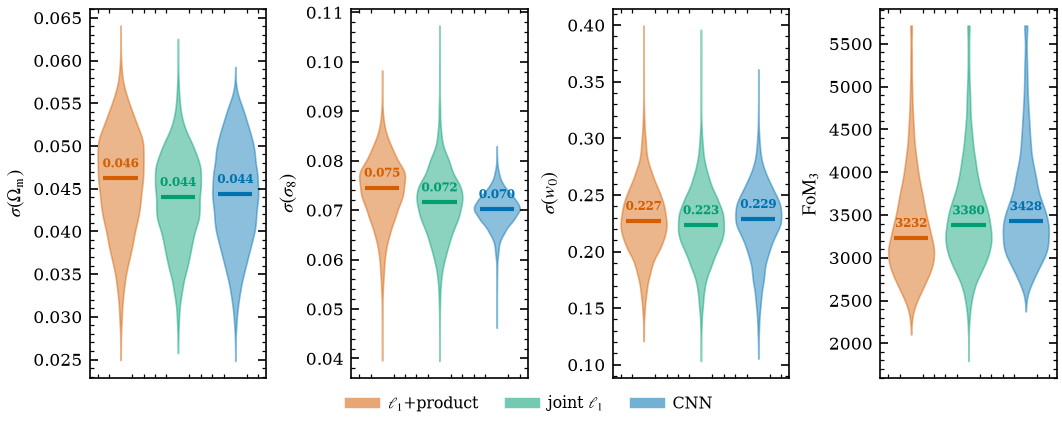

=== fig:data  (nn_l1_sbi.figures.fig_data)  exit=0  3.6 s
    wrote /path/to/nn_l1_sbi_out/figures/fig_data_flatlocal.pdf
    wrote /path/to/nn_l1_sbi_out/figures/_preview/fig_data.png
    wrote /path/to/nn_l1_sbi_out/figures/fig_data_flatlocal.pdf


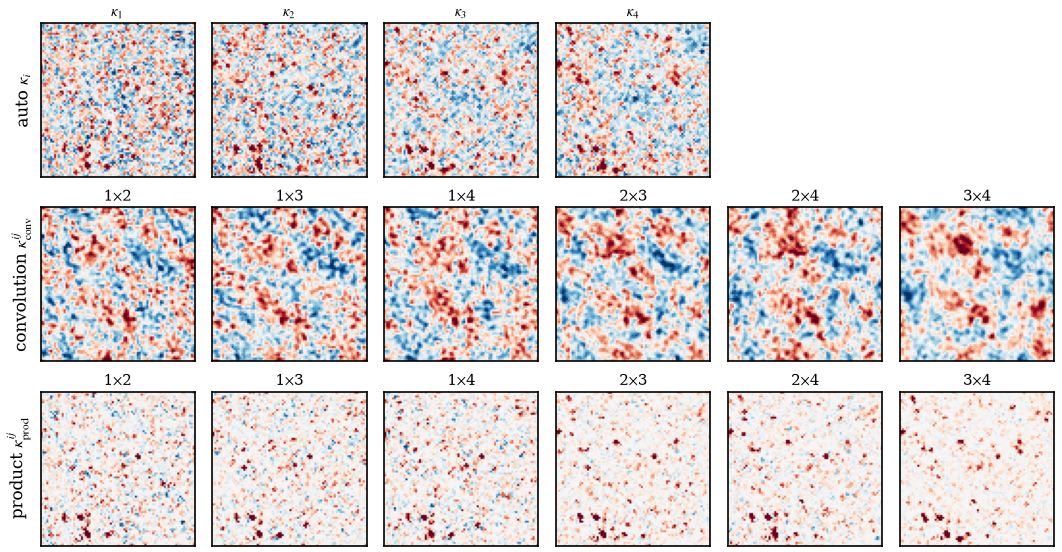

=== fig:pipeline  (nn_l1_sbi.figures.fig_pipeline)  exit=0  2.3 s
    wrote /path/to/nn_l1_sbi_out/figures/fig_pipeline.pdf
    wrote /path/to/nn_l1_sbi_out/figures/_preview/fig_pipeline.png
    wrote /path/to/nn_l1_sbi_out/figures/fig_pipeline.pdf


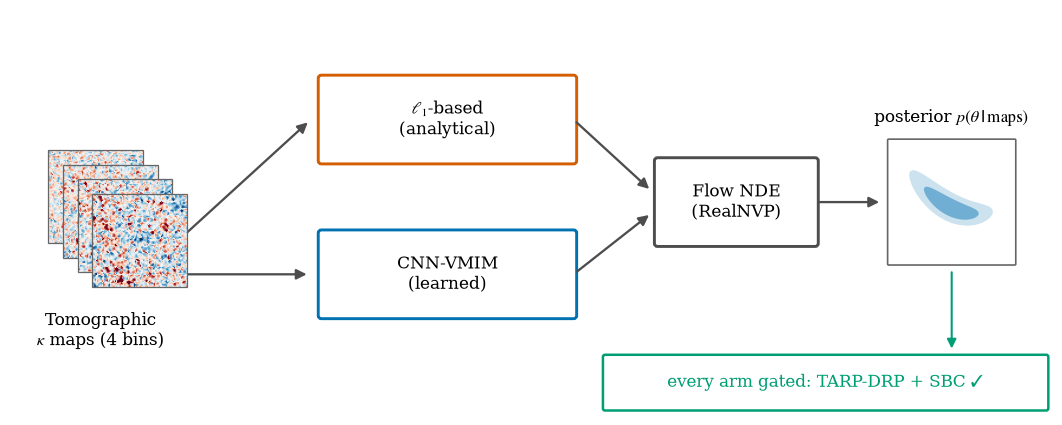

=== fig:leak (a)  (nn_l1_sbi.figures.fig_leak)  exit=0  8.8 s
    wrote /path/to/nn_l1_sbi_out/figures/fig_cross_leakage_scales.pdf | super-patch auto 0.8% cross 16.5%
    wrote /path/to/nn_l1_sbi_out/figures/_preview/fig_leak_a.png
    wrote /path/to/nn_l1_sbi_out/figures/fig_cross_leakage_scales.pdf


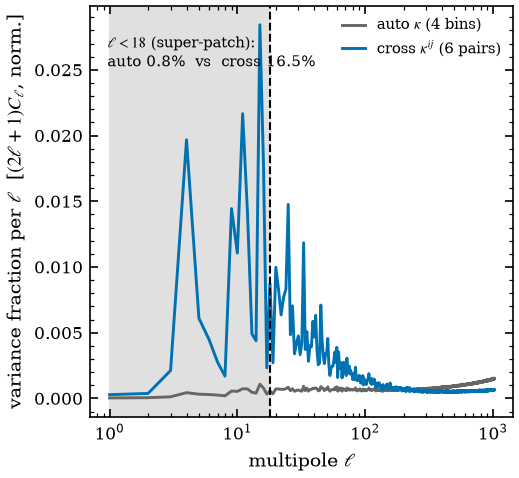

=== fig:leak (b)  (nn_l1_sbi.figures.fig_leak_maps)  exit=0  7.9 s
    wrote /path/to/nn_l1_sbi_out/figures/fig_fullsphere_maps.png
    wrote /path/to/nn_l1_sbi_out/figures/_preview/fig_leak_b.png
    wrote /path/to/nn_l1_sbi_out/figures/fig_fullsphere_maps.png


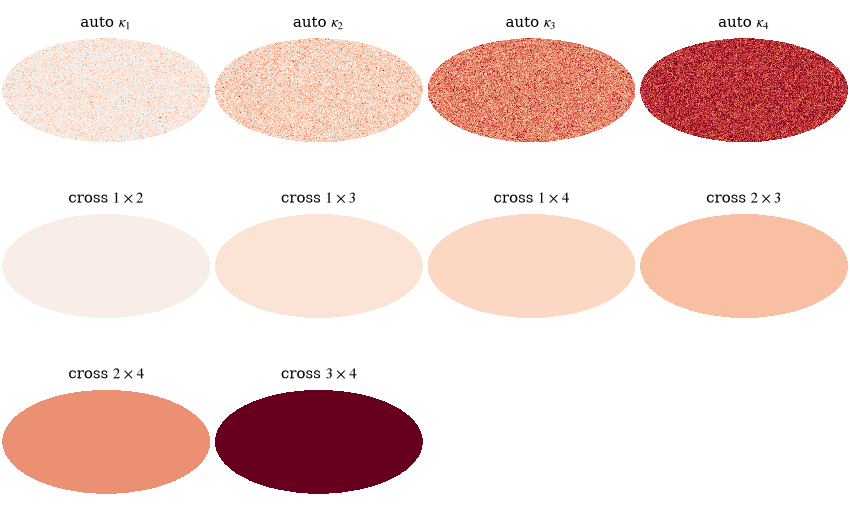

=== fig:fisher  (nn_l1_sbi.figures.fig_fisher)  exit=0  10.4 s
    wrote /path/to/nn_l1_sbi_out/figures/fig_fisher.pdf
    wrote /path/to/nn_l1_sbi_out/figures/_preview/fig_fisher.png
    wrote /path/to/nn_l1_sbi_out/figures/fig_fisher.pdf


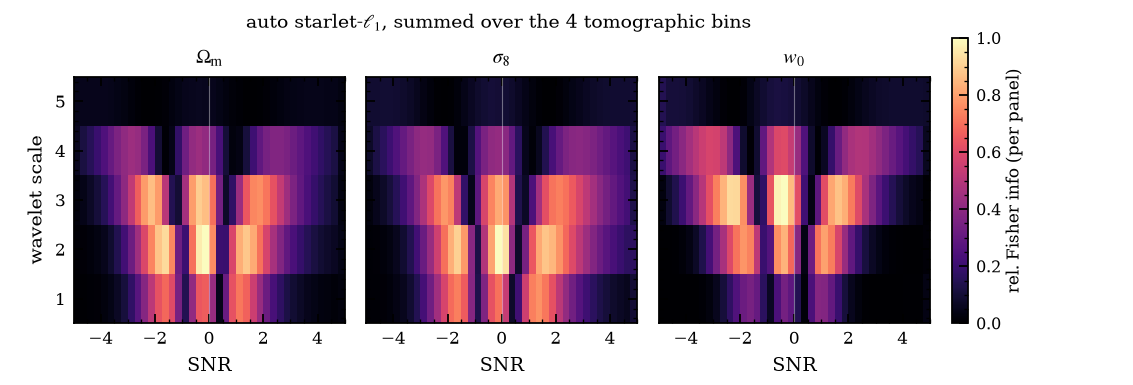

=== fig:embed  (nn_l1_sbi.figures.fig_embed)  exit=0  5.8 s
    wrote /path/to/nn_l1_sbi_out/figures/fig_embed.pdf
    wrote /path/to/nn_l1_sbi_out/figures/_preview/fig_embed.png
    wrote /path/to/nn_l1_sbi_out/figures/fig_embed.pdf


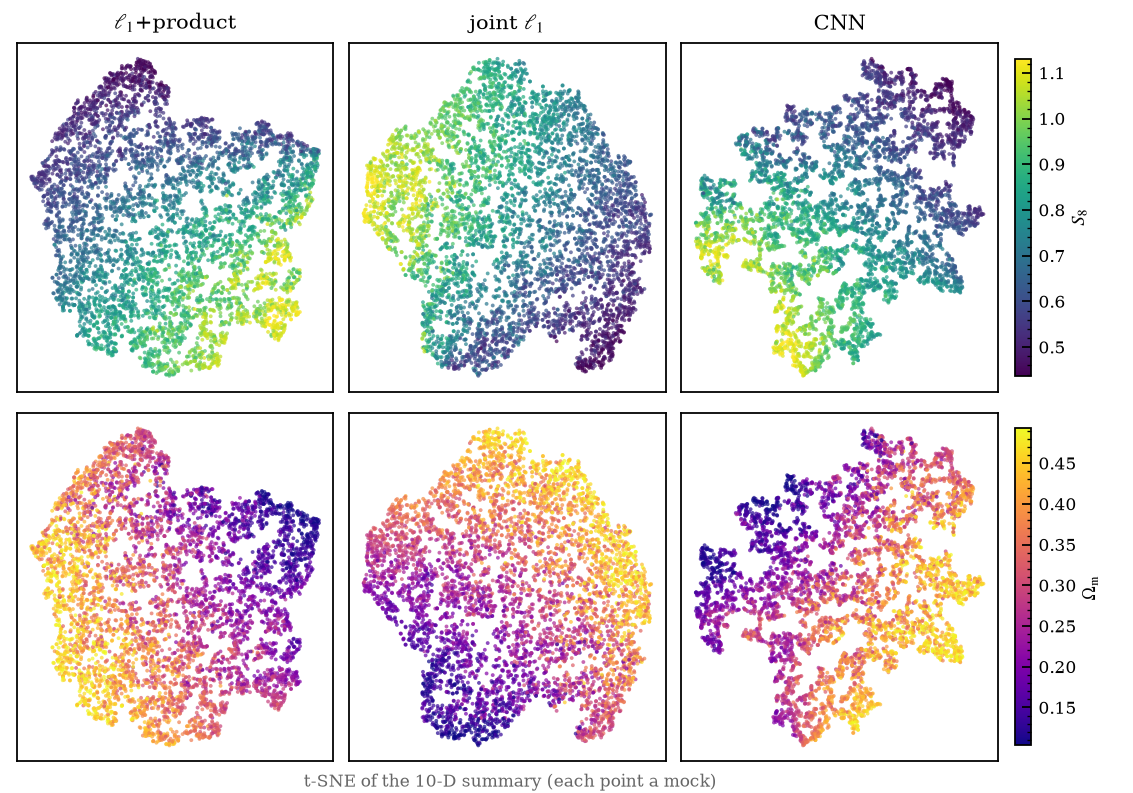


7/7 figures produced.


In [8]:
RUN_ONLY = None          # e.g. ["fig:cp"]; None = every READY figure
TIMEOUT_S = 1800

try:
    from IPython.display import Image, display
except ImportError:                                   # running outside Jupyter
    Image = display = None


def _snapshot():
    return {p: p.stat().st_mtime_ns for p in FIG_OUT.rglob("*")
            if p.suffix.lower() in (".pdf", ".png")} if FIG_OUT.is_dir() else {}


# The scripts run as their own module (python -m ...), exactly as the release runs them,
# so a source checkout needs src/ on the child's PYTHONPATH (an installed package does not,
# and prepending it is harmless there). NN_L1_SBI_OUT is pinned so the child writes where
# _snapshot() looks: output_root() defaults to ./nn_l1_sbi_out, which is cwd-dependent.
FIG_ENV = dict(os.environ,
               NN_L1_SBI_OUT=str(OUT_ROOT),
               PYTHONPATH=f"{SRC}{os.pathsep}{os.environ.get('PYTHONPATH', '')}".rstrip(os.pathsep),
               MPLBACKEND="Agg")


def run_figure(f):
    before = _snapshot()
    t0 = time.time()
    proc = subprocess.run([sys.executable, "-m", f["module"]], env=FIG_ENV,
                          cwd=str(REPO), capture_output=True, text=True, timeout=TIMEOUT_S)
    dt = time.time() - t0
    after = _snapshot()
    produced = sorted(p for p, m in after.items() if before.get(p) != m)
    print(f"=== {f['label']}  ({f['module']})  exit={proc.returncode}  {dt:.1f} s")
    for line in proc.stdout.strip().splitlines()[-6:]:
        print("   ", line)
    if proc.returncode != 0:
        print("    FAILED -- stderr tail:")
        for line in proc.stderr.strip().splitlines()[-15:]:
            print("   |", line)
        return False
    for p in produced:
        print(f"    wrote {p}")
    if display is not None:
        for p in produced:
            if p.parent.name == "_preview" and p.suffix == ".png":
                display(Image(filename=str(p)))
    return True


todo = [f for f in FIGURES if f["status"] == "READY"
        and (RUN_ONLY is None or f["label"] in RUN_ONLY)]
if not STYLE_OK:
    print("not running anything: paper.mplstyle is missing (see B.1) -- every figure script")
    print("fails at import until it is restored.")
elif not todo:
    print("no READY figure to run under this data root. Point $NN_L1_SBI_DATA at the unpacked")
    print("Zenodo bundle and re-run B.1. Sections A and C are unaffected.")
else:
    ok = sum(run_figure(f) for f in todo)
    print(f"\n{ok}/{len(todo)} figures produced.")

### B.4 — Where the shipped PDFs come from *(reference, nothing runs)*

The manuscript's figures were produced by exactly these scripts. Two of them
(`fig_leak*.py`, `fig_w0.py`, `fig_bntwhiten.py`, `fig_embed.py`) have working generators but are
**not cited** by the current manuscript — they are retained rather than deleted, and are marked
as such in `docs/FIGURE_MAP.md`.

If you have the original Jean-Zay analysis tree rather than the Zenodo bundle, the per-patch
inputs of `fig:cp` are the same runs under different directory names. **Verify before you link
anything**: each `per_patch_metrics.npz` stores its own provenance in the `arm_label` and
`arm_dirs` arrays — check those match the arm you think you are plotting, rather than trusting a
directory name.

---

# Section C — Optional end-to-end retrain (GPU, ~1 h)

**Opt-in only.** Every cell below starts with

```python
if os.environ.get("NN_L1_SBI_GPU") != "1":
    ...skip...
```

so a CPU reader can Run-All safely. To enable:

```bash
export NN_L1_SBI_GPU=1
export NN_L1_SBI_DATA=/path/to/the/writable/data/root     # raw l1 caches live here
```

What it does: retrain **one** VMIM compressor seed on the $\ell_1$ **auto, no-BNT** arm
(`vmim_from_cache`, 30 000 steps, ~35 min on one A100), then run the population sweep over the
9000 mocks on it (`population_sweep`, ~4 min), then compare the resulting FoM$_3$ against this
repository's own retrained value for that arm.

### Why it will not match exactly

The dominant term in the FoM$_3$ error budget is the **compressor training seed**: retraining the
compressor and re-running everything downstream moves FoM$_3$ by **~5–7 %**
(`docs/NOTE_FOM_ERROR_BARS.md` §3). Everything else is smaller — the NDE seed / family
contributes < 1.2 %, and the median's own sampling error over 9000 clustered mocks is 0.1–3 %.
On top of that, GPU non-determinism means even *the same* seed will not land on the same number
twice. A 5 % gate is therefore deliberately loose but not vacuous.

### What it is compared against, and why

The gate target is the **mean of the three retrained singles** `s41/s42/s43` of
`l1 auto, no-BNT` in `data/table1/` — **≈ 2772** (A.3 prints the three values; A.5 prints the
offset). It is **not** the published 2448, and **not** the retrained ensemble 2511. Two reasons:

* **estimator.** A single retrained compressor must be compared against retrained *singles*.
  In every row the 3-compressor ensemble sits below the mean of its singles — by 2–20 %, and
  by 9.4 % for this very arm — because pooling nine flows widens the posterior. "Never compare
  a retrained single against a published ensemble, or vice versa"
  (`scripts/slurm/CAMPAIGN_REFERENCE.md` §2).
* **provenance.** The published numbers were produced on different hardware before this
  reproduction. A.5 prints the retrained-vs-published offset for each of the ten rows that
  have a published value, every row in its own quoted estimator; they run from −1.2 % to
  +13.4 %, and this arm's is the *largest* of the ten (single vs single, +13.4 %). Gating on
  2448 would therefore fail a perfectly healthy rerun. (`CAMPAIGN_REFERENCE.md` §4 tabulates
  a different, ensemble-matched subset, +0.7 % to +5.6 % — not the same quantity as A.5.)
  The cell below prints the published comparison too, but does not gate on it.

### C.1 — Guard, configuration, preflight *(instant; skipped without `NN_L1_SBI_GPU=1`)*

Checks the inputs exist and prints the exact two commands that will be run. Nothing is trained
here.

In [9]:
if os.environ.get("NN_L1_SBI_GPU") != "1":
    print("Section C skipped (CPU-safe). Set NN_L1_SBI_GPU=1 to enable; needs 1 GPU and ~1 h.")
else:
    GPU_DATA = Path(os.environ.get("NN_L1_SBI_DATA", "")).expanduser()
    SEED = int(os.environ.get("NN_L1_SBI_SEED", "41"))
    TAG = f"none_nobnt_s{SEED}_repro"
    ARM_LABEL = f"auto_nobnt_s{SEED}_repro"

    # Flags below are the ones that produced Table 1; cross-check against
    # scripts/slurm/vmim_none_nobnt.slurm and scripts/slurm/sw_auto_nobnt_s41.slurm.
    CACHE_DIR = GPU_DATA / "l1_datavector_cache" / "flat_local_none"
    FID_NPZ = GPU_DATA / "fid_raw_none.npz"
    OUT_CACHE = GPU_DATA / "vmim" / TAG
    OUT_FID = OUT_CACHE / "fiducial_summaries.npz"
    SWEEP_OUT = GPU_DATA / "sweeps" / ARM_LABEL

    VMIM_CMD = [sys.executable, "-u", "-m", "nn_l1_sbi.compression.vmim_from_cache",
                "--cache-dir", str(CACHE_DIR),
                "--fid-npz", str(FID_NPZ),
                "--out-cache", str(OUT_CACHE),
                "--out-fid", str(OUT_FID),
                "--summary-dim", "10", "--hidden", "256,256",
                "--nf-layers", "4", "--nf-hidden", "128",
                "--steps", "30000", "--seed", str(SEED),
                "--preproc-transform", "log1p-zscore", "--clip-value", "5",
                "--min-feature-variance", "1e-5",
                "--max-minutes", "35", "--cuda-visible-devices", "0"]
    SWEEP_CMD = [sys.executable, "-u", "-m", "nn_l1_sbi.inference.population_sweep",
                 "--arm-dir", str(OUT_CACHE),
                 "--arm-label", ARM_LABEL,
                 "--out", str(SWEEP_OUT),
                 "--seeds", "41,42,43", "--n-obs", "9000",
                 "--max-perm", "50", "--m-samples", "2000"]

    missing = [p for p in (CACHE_DIR, FID_NPZ) if not p.exists()]
    print(f"data root : {GPU_DATA}")
    print(f"seed      : {SEED}   (the paper's compressor seeds are 41, 42, 43)")
    print(f"cache-dir : {CACHE_DIR}  {'OK' if CACHE_DIR.exists() else 'MISSING'}")
    print(f"fid-npz   : {FID_NPZ}  {'OK' if FID_NPZ.exists() else 'MISSING'}")
    print(f"out       : {OUT_CACHE}  ->  {SWEEP_OUT}")
    print()
    print("step 1 (~35 min):", " ".join(VMIM_CMD[2:]))
    print()
    print("step 2 (~4 min) :", " ".join(SWEEP_CMD[2:]))
    if missing:
        print()
        print("PREFLIGHT FAILED -- these inputs are absent, so C.2/C.3 will not run:")
        for p in missing:
            print("   ", p)
        print("The raw 800-D l1 datavector caches are the 35 GB tier; they are not on Zenodo.")
    else:
        print()
        print("preflight OK.")
    C_READY = not missing

Section C skipped (CPU-safe). Set NN_L1_SBI_GPU=1 to enable; needs 1 GPU and ~1 h.


### C.2 — Retrain one VMIM compressor *(GPU, ~35 min; skipped without `NN_L1_SBI_GPU=1`)*

`nn_l1_sbi.compression.vmim_from_cache`, with the flags of
`scripts/slurm/vmim_none_nobnt.slurm` — summary dim 10, hidden 256,256, RealNVP 4×128,
30 000 steps, `log1p-zscore` preprocessing with clip 5 and min-variance 1e-5. Output goes to a
`*_repro` directory, so nothing that Table 1 depends on is overwritten.

The SLURM job runs the same command under `srun` on an allocated node; here it runs directly on
whatever GPU the notebook kernel sees.

In [10]:
if os.environ.get("NN_L1_SBI_GPU") != "1":
    print("Section C skipped (CPU-safe). Set NN_L1_SBI_GPU=1 to enable.")
elif not C_READY:
    print("C.1 preflight failed -- not training. See the missing inputs above.")
else:
    env = dict(os.environ, PYTHONPATH=f"{SRC}{os.pathsep}{os.environ.get('PYTHONPATH', '')}",
               TF_CPP_MIN_LOG_LEVEL="3", XLA_PYTHON_CLIENT_PREALLOCATE="false")
    t0 = time.time()
    proc = subprocess.run(VMIM_CMD, cwd=str(REPO), env=env, text=True,
                          capture_output=True, timeout=4 * 3600)
    print(f"exit={proc.returncode}  {(time.time() - t0) / 60:.1f} min")
    for line in proc.stdout.strip().splitlines()[-20:]:
        print("   ", line)
    if proc.returncode != 0:
        for line in proc.stderr.strip().splitlines()[-20:]:
            print("   |", line)
        raise RuntimeError("vmim_from_cache failed -- see stderr above")
    meta = OUT_CACHE / "l1_cache_meta.npz"
    if meta.exists():
        z = np.load(meta, allow_pickle=True)
        print("cache meta:", {k: z[k].item() if z[k].shape == () else z[k].tolist()
                              for k in ("summary_dim", "steps_run", "best_step", "best_val", "seed")
                              if k in z})

Section C skipped (CPU-safe). Set NN_L1_SBI_GPU=1 to enable.


### C.3 — Population sweep on the new compressor *(GPU, ~4 min; skipped without `NN_L1_SBI_GPU=1`)*

`nn_l1_sbi.inference.population_sweep` with the flags of
`scripts/slurm/sw_auto_nobnt_s41.slurm`: NDE seeds 41,42,43 pooled, 9000 mock observations
(180 patches × 50 noise realisations), 2000 posterior draws each. Writes
`median_summary.json`, `per_patch_metrics.npz` and `per_obs_samples.npy` (~216 MB) into the
`*_repro` sweep directory.

In [11]:
if os.environ.get("NN_L1_SBI_GPU") != "1":
    print("Section C skipped (CPU-safe). Set NN_L1_SBI_GPU=1 to enable.")
elif not C_READY:
    print("C.1 preflight failed -- not sweeping.")
else:
    env = dict(os.environ, PYTHONPATH=f"{SRC}{os.pathsep}{os.environ.get('PYTHONPATH', '')}",
               TF_CPP_MIN_LOG_LEVEL="3", XLA_PYTHON_CLIENT_PREALLOCATE="false")
    t0 = time.time()
    proc = subprocess.run(SWEEP_CMD, cwd=str(REPO), env=env, text=True,
                          capture_output=True, timeout=4 * 3600)
    print(f"exit={proc.returncode}  {(time.time() - t0) / 60:.1f} min")
    for line in proc.stdout.strip().splitlines()[-20:]:
        print("   ", line)
    if proc.returncode != 0:
        for line in proc.stderr.strip().splitlines()[-20:]:
            print("   |", line)
        raise RuntimeError("population_sweep failed -- see stderr above")

Section C skipped (CPU-safe). Set NN_L1_SBI_GPU=1 to enable.


### C.4 — Compare against Table 1 *(instant; skipped without `NN_L1_SBI_GPU=1`)*

Gate: the new FoM$_3$ must be within `NN_L1_SBI_FOM_TOL` (default **5 %**) of
`BY_LABEL["l1 auto, no-BNT"]["mean"]` — the mean of the three **retrained singles** in
`data/table1/`, **≈ 2772**. That is the quantity the assertion below uses, and it is neither
the published 2448 nor the retrained ensemble 2511; the cell prints all three so the comparison
cannot be misread.

Read the result honestly. A 3 % miss is a compressor seed; a 40 % miss is a broken pipeline. If
the gate fails by a little, look at the spread of the three committed singles printed alongside —
it is the empirical scale of exactly this effect.

In [12]:
if os.environ.get("NN_L1_SBI_GPU") != "1":
    print("Section C skipped (CPU-safe). Set NN_L1_SBI_GPU=1 to enable.")
else:
    summary = SWEEP_OUT / "median_summary.json" if C_READY else None
    if summary is None:
        print("nothing to check: the C.1 preflight failed, so C.2/C.3 did not run.")
    elif not summary.exists():
        print(f"nothing to check: {summary} does not exist -- run C.2 and C.3 first.")
    else:
        with open(summary) as fh:
            got = json.load(fh)
        ref = BY_LABEL["l1 auto, no-BNT"]
        target = ref["mean"]                       # mean of the three retrained singles
        tol = float(os.environ.get("NN_L1_SBI_FOM_TOL", "0.05"))
        delta = (got["fom3"] - target) / target

        print(f"retrained now      : FoM3 = {got['fom3']:.1f}   "
              f"(arm {got['arm']}, n = {got['n']}, n_members = {got['n_members']})")
        print(f"committed singles  : {['%.1f' % v for v in ref['per_seed']]}  "
              f"mean {target:.1f}  std {ref['std']:.1f}  ({100 * ref['rel']:.2f} %)")
        print(f"delta vs singles   : {100 * delta:+.2f} %   (gate: +-{100 * tol:.0f} %)")
        print(f"committed ensemble : {ref['ensemble']:.1f}   "
              f"(do NOT compare a single against this)")
        print(f"published (paper)  : {ref['published']}   "
              f"delta {100 * (got['fom3'] - ref['published']) / ref['published']:+.1f} % "
              f"-- reported, not gated (see the section header)")
        for k, lab in (("sigma_Om", "sigma(Om)"), ("sigma_s8", "sigma(s8)"),
                       ("sigma_w0", "sigma(w0)")):
            j = PARAMS.index(k)
            print(f"{lab:<19}: {got[k]:.4f}   committed s41 {ref['sigma'][j]:.4f}   "
                  f"{100 * (got[k] - ref['sigma'][j]) / ref['sigma'][j]:+.1f} %")

        assert abs(delta) <= tol, (
            f"FoM3 {got['fom3']:.1f} is {100 * delta:+.1f} % from the committed retrained "
            f"singles mean {target:.1f} -- outside the +-{100 * tol:.0f} % gate. Compressor-seed "
            "variance is ~5-7 % (docs/NOTE_FOM_ERROR_BARS.md section 3), so a small overshoot is "
            "seed noise; a large one is a pipeline problem.")
        print(f"\nOK: within +-{100 * tol:.0f} % of the committed retrained value.")

Section C skipped (CPU-safe). Set NN_L1_SBI_GPU=1 to enable.


---

## Provenance

| what | where |
|---|---|
| Table-1 inputs (committed, 43 kB) | `data/table1/` — see its `README.md` for the full schema |
| error-bar definition | `docs/NOTE_FOM_ERROR_BARS.md` |
| figure → data → generator map | `docs/FIGURE_MAP.md`, `src/nn_l1_sbi/figures/_data.py` |
| the exact SLURM recipes | `scripts/slurm/` (`vmim_*.slurm`, `sw_*.slurm`) |
| verified constants (geometry, noise, FoM$_3$) | `scripts/slurm/CAMPAIGN_REFERENCE.md` §3 |
